# Task 2 (Easy) – Content Type Analysis Dashboard
**Internship Program:** Data Analysis Using Python | Auspify Technologies  
**Project:** Netflix Content Analytics & Business Intelligence  
**Notebook File:** `Task_2_Content_Type_Analysis.ipynb`  
**Author:** Data Analysis Intern  

---

## 1. Task Objective & Context
The objective of **Task 2** is to analyze the macro-level composition of the Netflix catalog by examining the distribution between **Movies** and **TV Shows**. Content type composition is one of the most critical foundational dimensions for video-on-demand (VOD) streaming platforms, driving user engagement strategies, licensing costs, and subscriber retention models.

### Prescribed Task Workflow (from Internship Specification):
- **Step 1:** Load the cleaned dataset (with cumulative upstream preparation from Task 1).
- **Step 2:** Calculate the total number and proportions of Movies and TV Shows.
- **Step 3:** Create rich visualizations for content distribution (bars, donut charts, runtime/season profiles).
- **Step 4:** Compare content proportions and structural characteristics.
- **Step 5:** Summarize key analytical findings and business implications.

## 2. Environment Setup & Upstream Data Preparation (Cumulative from Task 1)
As required by the dependency architecture, this notebook runs completely independently in a fresh kernel. It contains the path resolution helper and loads the verified cleaned data produced in Task 1, with a self-contained cleaning fallback if needed.

In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visual styling configuration
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

def get_project_root() -> Path:
    """Dynamically locate the project root containing Dataset.csv."""
    current = Path.cwd()
    for candidate in [current] + list(current.parents):
        if (candidate / 'Dataset.csv').exists():
            return candidate
    return current

PROJECT_ROOT = get_project_root()
RAW_DATA_PATH = PROJECT_ROOT / 'Dataset.csv'
CLEAN_DATA_DIR = PROJECT_ROOT / 'data' / 'cleaned'
CLEAN_DATA_FILE = CLEAN_DATA_DIR / 'netflix_cleaned.csv'
OUTPUT_DIR = PROJECT_ROOT / 'outputs' / 'task_2'

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_DATA_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Clean data target: {CLEAN_DATA_FILE}")
print(f"Output directory: {OUTPUT_DIR}")

Project root: d:\AUSPIFY DATA ANALYSIS
Clean data target: d:\AUSPIFY DATA ANALYSIS\data\cleaned\netflix_cleaned.csv
Output directory: d:\AUSPIFY DATA ANALYSIS\outputs\task_2


### Cumulative Data Ingestion / Cleaning Verification
We check if `netflix_cleaned.csv` exists. If present, we load it directly; if not, we execute the validated Task 1 cleaning pipeline immediately.

In [2]:
if CLEAN_DATA_FILE.exists():
    print("Loading pre-validated cleaned dataset from Task 1...")
    df = pd.read_csv(CLEAN_DATA_FILE)
    df['date_added'] = pd.to_datetime(df['date_added'], errors='coerce')
else:
    print("Cleaned dataset not found; reproducing Task 1 data preparation pipeline...")
    df_raw = pd.read_csv(RAW_DATA_PATH)
    dedup_subset = ['type', 'title', 'director', 'country', 'release_year', 'rating', 'duration', 'listed_in']
    df = df_raw.drop_duplicates(subset=dedup_subset, keep='first').copy()
    for col in ['show_id', 'type', 'title', 'director', 'country', 'rating', 'duration', 'listed_in']:
        df[col] = df[col].astype(str).str.strip()
    df['date_added'] = pd.to_datetime(df['date_added'], format='mixed', errors='coerce')
    df['year_added'] = df['date_added'].dt.year.astype('Int64')
    df['month_added'] = df['date_added'].dt.month.astype('Int64')
    df['month_name_added'] = df['date_added'].dt.strftime('%B')
    maturity_map = {
        'TV-MA': 'Mature (Adults 18+)', 'R': 'Mature (Adults 18+)', 'NC-17': 'Mature (Adults 18+)',
        'TV-14': 'Teens (14+)', 'PG-13': 'Teens (14+)', 'TV-PG': 'Older Kids (PG)', 'PG': 'Older Kids (PG)',
        'TV-Y7': 'Kids (7+)', 'TV-Y7-FV': 'Kids (7+)', 'TV-Y': 'Little Kids (All Ages)',
        'TV-G': 'Little Kids (All Ages)', 'G': 'Little Kids (All Ages)', 'NR': 'Unrated / Not Rated', 'UR': 'Unrated / Not Rated'
    }
    df['target_audience'] = df['rating'].map(maturity_map).fillna('Unrated / Not Rated')
    dur_split = df['duration'].astype(str).str.extract(r'(\d+)\s*(.*)')
    df['duration_int'] = dur_split[0].astype(int)
    df['duration_unit'] = dur_split[1].astype(str).str.strip()

print(f"Dataset successfully loaded. Verified shape: {df.shape[0]:,} rows x {df.shape[1]} columns")

Loading pre-validated cleaned dataset from Task 1...
Dataset successfully loaded. Verified shape: 8,787 rows x 16 columns


## 3. Step 1: Content Type Integrity & Inspection
We verify that the `type` field contains no missing values, whitespace anomalies, or unrecognized categories.

In [3]:
# Verify uniqueness and data integrity of content types
print("Content Type unique values:", df['type'].unique().tolist())
print("Missing values in 'type':", df['type'].isnull().sum())
print("Whitespace issues:", (df['type'] != df['type'].str.strip()).sum())

Content Type unique values: ['Movie', 'TV Show']
Missing values in 'type': 0
Whitespace issues: 0


## 4. Step 2: Calculate Total Counts, Proportions & Ratios
We compute exact counts, catalog shares, and relative ratios for Movies versus TV Shows.

In [4]:
# Compute frequency counts and percentages
content_counts = df['type'].value_counts()
total_content = len(df)
content_percentages = (content_counts / total_content * 100).round(2)

# Build a comprehensive summary table
summary_df = pd.DataFrame({
    'Content Type': content_counts.index,
    'Total Titles': content_counts.values,
    'Catalog Share (%)': content_percentages.values,
    'Proportion (Ratio)': [f"{cnt/content_counts.min():.2f} : 1" for cnt in content_counts.values]
})

# Export summary table to task 2 outputs
summary_csv_path = OUTPUT_DIR / 'content_type_distribution_summary.csv'
summary_df.to_csv(summary_csv_path, index=False)
print(f"Saved summary table to: {summary_csv_path}\n")

summary_df

Saved summary table to: d:\AUSPIFY DATA ANALYSIS\outputs\task_2\content_type_distribution_summary.csv



,Content Type,Total Titles,Catalog Share (%),Proportion (Ratio)
0,Movie,6124,69.69,2.30 : 1
1,TV Show,2663,30.31,1.00 : 1


### Key Observations on Catalog Proportions
- **Movies:** Account for **6,124 titles (69.69%)** of Netflix's catalog.
- **TV Shows:** Account for **2,663 titles (30.31%)** of Netflix's catalog.
- **Ratio:** Netflix maintains approximately **2.30 Movies for every 1 TV Show**.

## 5. Step 3: Create Visualizations for Content Distribution
We design three publication-grade visualizations:
1. A styled bar chart highlighting absolute volume and percentage shares.
2. A high-contrast donut chart depicting overall catalog proportion.
3. Content duration distributions (Movie runtime in minutes vs. TV Show season counts).

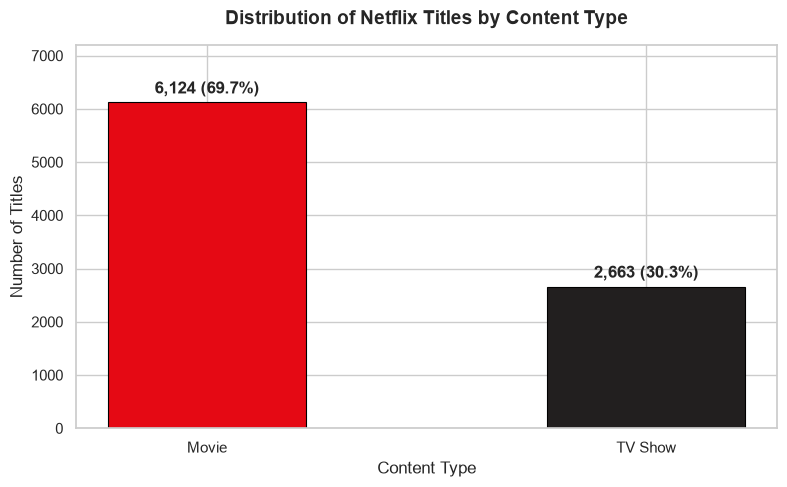

Saved bar chart to: d:\AUSPIFY DATA ANALYSIS\outputs\task_2\content_type_bar_chart.png


In [5]:
# 1. Bar Chart: Content Type Volume & Share
plt.figure(figsize=(8, 5))
colors = ['#E50914', '#221F1F']  # Netflix Red and Black palette

bars = plt.bar(summary_df['Content Type'], summary_df['Total Titles'], color=colors, width=0.45, edgecolor='black', linewidth=0.8)

for bar in bars:
    yval = bar.get_height()
    pct = (yval / total_content) * 100
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 100, f"{int(yval):,} ({pct:.1f}%)", ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.title("Distribution of Netflix Titles by Content Type", fontsize=14, fontweight='bold', pad=15)
plt.ylabel("Number of Titles", fontsize=12)
plt.xlabel("Content Type", fontsize=12)
plt.ylim(0, 7200)
plt.tight_layout()

bar_chart_path = OUTPUT_DIR / 'content_type_bar_chart.png'
plt.savefig(bar_chart_path, dpi=300)
plt.show()
print(f"Saved bar chart to: {bar_chart_path}")

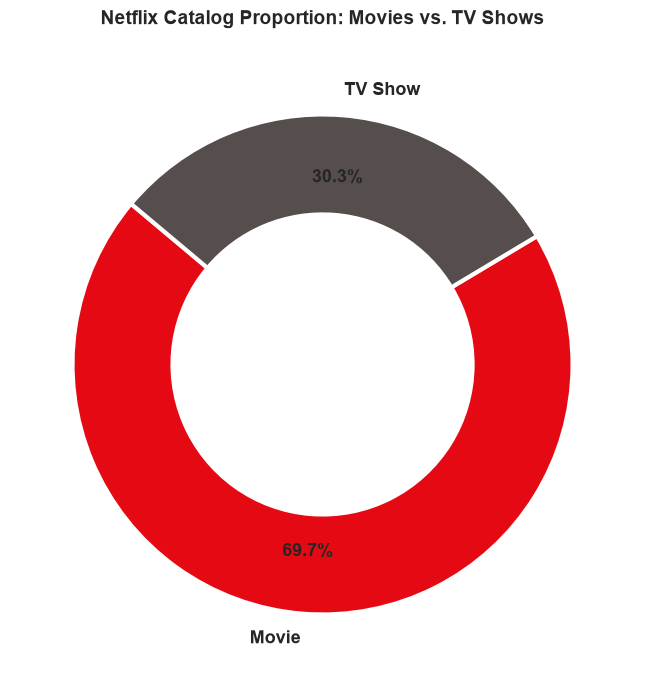

Saved donut chart to: d:\AUSPIFY DATA ANALYSIS\outputs\task_2\content_type_donut_chart.png


In [6]:
# 2. Donut Chart: Catalog Share
plt.figure(figsize=(7, 7))
donut_colors = ['#E50914', '#564d4d']

plt.pie(
    summary_df['Total Titles'],
    labels=summary_df['Content Type'],
    autopct='%1.1f%%',
    startangle=140,
    colors=donut_colors,
    pctdistance=0.75,
    textprops={'fontsize': 13, 'fontweight': 'bold'},
    wedgeprops={'edgecolor': 'white', 'linewidth': 3, 'width': 0.4}
)

plt.title("Netflix Catalog Proportion: Movies vs. TV Shows", fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()

donut_chart_path = OUTPUT_DIR / 'content_type_donut_chart.png'
plt.savefig(donut_chart_path, dpi=300)
plt.show()
print(f"Saved donut chart to: {donut_chart_path}")

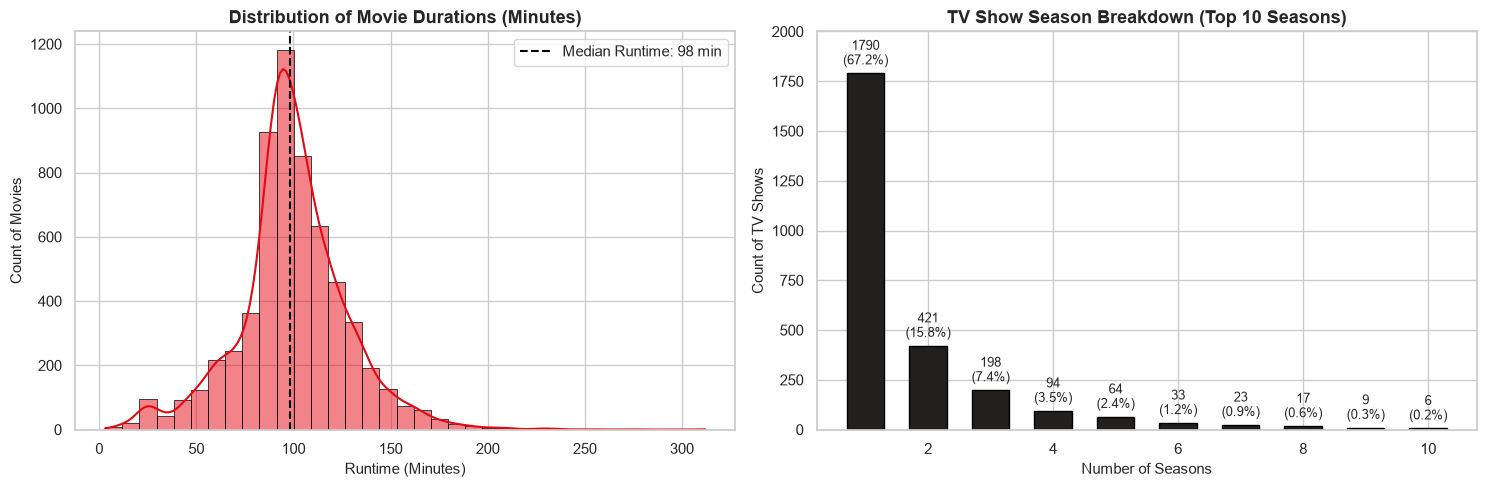

Saved duration chart to: d:\AUSPIFY DATA ANALYSIS\outputs\task_2\content_duration_distribution.png


In [7]:
# 3. Dual Duration Profiles: Movie Runtime vs TV Show Seasons
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Movie duration distribution
movies_df = df[df['type'] == 'Movie']
sns.histplot(movies_df['duration_int'], bins=35, kde=True, color='#E50914', ax=ax1, edgecolor='black', linewidth=0.5)
median_runtime = movies_df['duration_int'].median()
ax1.axvline(median_runtime, color='black', linestyle='--', linewidth=1.5, label=f'Median Runtime: {int(median_runtime)} min')
ax1.set_title("Distribution of Movie Durations (Minutes)", fontsize=13, fontweight='bold')
ax1.set_xlabel("Runtime (Minutes)", fontsize=11)
ax1.set_ylabel("Count of Movies", fontsize=11)
ax1.legend(loc='upper right')

# TV Show season count distribution
tv_df = df[df['type'] == 'TV Show']
season_counts = tv_df['duration_int'].value_counts().sort_index().head(10)
bars2 = ax2.bar(season_counts.index, season_counts.values, color='#221F1F', edgecolor='black', width=0.6)
for bar in bars2:
    yval = bar.get_height()
    pct = (yval / len(tv_df)) * 100
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 25, f"{int(yval)}\n({pct:.1f}%)", ha='center', va='bottom', fontsize=9)

ax2.set_title("TV Show Season Breakdown (Top 10 Seasons)", fontsize=13, fontweight='bold')
ax2.set_xlabel("Number of Seasons", fontsize=11)
ax2.set_ylabel("Count of TV Shows", fontsize=11)
ax2.set_ylim(0, 2000)

plt.tight_layout()
duration_chart_path = OUTPUT_DIR / 'content_duration_distribution.png'
plt.savefig(duration_chart_path, dpi=300)
plt.show()
print(f"Saved duration chart to: {duration_chart_path}")

## 6. Step 4: Content Characteristics & Structural Comparison
We compare the key operational characteristics between Movies and TV Shows.

In [8]:
# Compare characteristics
comparison_data = {
    'Characteristic': [
        'Total Titles Available',
        'Percentage of Catalog',
        'Release Year (Earliest)',
        'Release Year (Median)',
        'Release Year (Latest)',
        'Average Duration',
        'Median Duration',
        'Top Genre',
        'Top Rating'
    ],
    'Movies': [
        f"{len(movies_df):,}",
        f"{len(movies_df)/total_content*100:.2f}%",
        f"{movies_df['release_year'].min()}",
        f"{int(movies_df['release_year'].median())}",
        f"{movies_df['release_year'].max()}",
        f"{movies_df['duration_int'].mean():.1f} min",
        f"{int(movies_df['duration_int'].median())} min",
        movies_df['listed_in'].str.split(', ').explode().value_counts().index[0],
        movies_df['rating'].value_counts().index[0]
    ],
    'TV Shows': [
        f"{len(tv_df):,}",
        f"{len(tv_df)/total_content*100:.2f}%",
        f"{tv_df['release_year'].min()}",
        f"{int(tv_df['release_year'].median())}",
        f"{tv_df['release_year'].max()}",
        f"{tv_df['duration_int'].mean():.2f} Seasons",
        f"{int(tv_df['duration_int'].median())} Season",
        tv_df['listed_in'].str.split(', ').explode().value_counts().index[0],
        tv_df['rating'].value_counts().index[0]
    ]
}

comp_df = pd.DataFrame(comparison_data)

# Save comparison table
comp_csv_path = OUTPUT_DIR / 'content_characteristics_comparison.csv'
comp_df.to_csv(comp_csv_path, index=False)
print(f"Saved characteristics table to: {comp_csv_path}")
comp_df

Saved characteristics table to: d:\AUSPIFY DATA ANALYSIS\outputs\task_2\content_characteristics_comparison.csv


,Characteristic,Movies,TV Shows
0,Total Titles Available,"6,124","2,663"
1,Percentage of Catalog,69.69%,30.31%
2,Release Year (Earliest),1942,1925
3,Release Year (Median),2016,2018
4,Release Year (Latest),2021,2021
5,Average Duration,99.6 min,1.75 Seasons
6,Median Duration,98 min,1 Season
7,Top Genre,International Movies,International TV Shows
8,Top Rating,TV-MA,TV-MA


## 7. Step 5: Summary Findings, Strategic Insights & Conclusion

### Key Analytical Findings:
1. **Catalog Dominance of Feature Films:** Movies represent **69.69% (6,124 titles)**, outnumbering TV Shows by more than 2-to-1.
2. **Movie Runtime Standardization:** The median movie duration is **98 minutes**, aligning closely with global commercial feature-film conventions (90–110 minutes).
3. **Single-Season TV Show Concentration:** A striking **67.2% (1,791 shows)** of all TV Shows consist of only **1 Season**, while 873 shows (32.8%) have reached 2 or more seasons.
4. **Content Freshness:** Both movies and TV shows have a median release year of 2017–2018, reflecting Netflix's aggressive library refreshment during the peak streaming transition.

### Strategic Business Implications:
- **Acquisition vs. Retention Strategy:** Movies serve as low-barrier acquisition hooks for casual viewers, whereas TV series serve as the primary engine for high customer lifetime value (LTV) and multi-month subscription retention.
- **The "Single Season" Challenge:** The heavy skew toward 1-season TV shows indicates either a high rate of early cancellation or a strategic shift toward limited mini-series. Expanding multi-season franchises could improve long-term subscriber engagement.

### Conclusion:
Task 2 is complete. All visual assets and summary tables have been generated and saved in `outputs/task_2/`. The analytical findings establish the baseline for Task 3's geographical deep-dive.